## Setup (run this first)
This cell finds the project files automatically: current folder, then the group GitHub repo, then a shared Drive folder, then a zip upload. Everyone (group members and the instructor) can run it without editing paths.

In [ ]:
# ---- Setup: works for any group member, the instructor, Colab or a laptop ------------------------------
# Order tried: (1) the files are already in the current folder, (2) Member3_Baseline_NLP.zip is already uploaded
# (Colab file panel or next to this notebook), (3) the shared Google Drive zip (downloaded, no sign-in),
# (4) the group GitHub repo, (5) an already-mounted Drive folder, (6) you upload the zip when asked. Nothing needs editing.
import os, sys, glob, zipfile, subprocess
REPO_URL = os.environ.get("REPO_URL", "https://github.com/jijjira/anlp-at2b-study-to-career.git")
DRIVE_DIR = "/content/drive/MyDrive/ANLP AT2B"
DRIVE_ZIP_ID = "1pgnI7O_CHeXK7RRtrGqA-XA7dKOvW6G_"   # Member3_Baseline_NLP.zip in the shared Drive folder
NEEDED = ["alignment.py", "extraction.py", "make_sample_pdf.py", "skill_extractor.py", "skill_extractor_v2.py", "job_cleaned.csv",
          "skills_dictionary.csv", "normalisation.py", "extra_aliases_reviewed.csv"]
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False
def have_all(d="."): return all(os.path.exists(os.path.join(d, f)) for f in NEEDED)
def use(folder): os.chdir(folder); print("Using folder:", os.getcwd())
def code_folder(root):
    hits = glob.glob(os.path.join(root, "**", "skill_extractor_v2.py"), recursive=True)
    return os.path.dirname(hits[0]) if hits else None
def from_zip(z):
    out = "/content/m3" if IN_COLAB else os.path.join(os.path.dirname(os.path.abspath(z)), "_m3")
    zipfile.ZipFile(z).extractall(out); f = code_folder(out)
    if f: use(f)
START = os.getcwd()
if not have_all():                                   # (2) a zip that is already there
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        if "Member3" in os.path.basename(z) and not have_all(): from_zip(z)
if not have_all():                                   # (3) the public Drive zip (one file, no sign-in needed)
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
        import gdown
        zdir = "/content" if IN_COLAB else START
        zp = gdown.download(id=DRIVE_ZIP_ID, output=os.path.join(zdir, "Member3_Baseline_NLP.zip"), quiet=True)
        if zp and zipfile.is_zipfile(zp): from_zip(zp)
        else: print("Could not download the zip from Drive, trying the next option.")
    except Exception:
        print("Could not download the zip from Drive, trying the next option.")
if not have_all():                                   # (4) group repo (works only if it is public or you are signed in)
    dest = "/content/_repo" if IN_COLAB else os.path.join(START, "_repo")
    if not os.path.exists(dest):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, dest], capture_output=True, text=True, env=env)
        if r.returncode != 0: print("Could not clone the repo (it may be private), trying the next option.")
    f = code_folder(dest) if os.path.exists(dest) else None
    if f: use(f)
if not have_all() and os.path.isdir(DRIVE_DIR) and have_all(DRIVE_DIR): use(DRIVE_DIR)   # (5) Drive, only if already mounted
if not have_all() and IN_COLAB:                      # (6) ask for the zip; never save into the Drive mount
    os.chdir("/content")
    print("Please choose Member3_Baseline_NLP.zip (from the group Drive or the submission).")
    from google.colab import files
    for name in files.upload():
        if name.endswith(".zip") and not have_all(): from_zip(os.path.join("/content", name))
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy", "pymupdf", "reportlab"], check=False)
missing = [f for f in NEEDED if not os.path.exists(f)]
print("Working folder:", os.getcwd()); print("Missing files:", missing if missing else "none, good to go")


# 06 · Curriculum alignment with uncertainty (Member 3)
**RQ2: how well does a curriculum cover what the U.S. Data/AI market demands?** The U.S. ads are a *benchmark*, not a forecast of Australian hiring.

Three ideas that go beyond counting skill mentions:
1. **Coverage strength.** A skill that is *assessed* is not the same as one that is merely *mentioned*. Study material is tagged assessed (1.0), taught (0.75) or mentioned (0.5), mirroring the required/preferred idea on the job side.
2. **Uncertainty.** Career fit is reported with a bootstrap range over the job ads, not as one falsely precise number.
3. **Whole curriculum.** Several units are merged into one view, with the skills that the market demands most but the curriculum does not cover.

> **Important.** The four units below are **synthetic demo units** written for this notebook. No result here is a finding about a real UTS degree. Replace them with real outlines (see the last section) before drawing any conclusion.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from extraction import analyse_text, analyse_study_material, COVERAGE_WEIGHTS
from alignment import DemandModel, job_strengths, curriculum_coverage
from skill_extractor_v2 import RequirementAwareExtractor
jobs = pd.read_csv("job_cleaned.csv", encoding="utf-8-sig")
EX = RequirementAwareExtractor(extra_aliases_path="extra_aliases_reviewed.csv", expand_morphology=True)
S = job_strengths(jobs.job_description, EX)
M = DemandModel(S, jobs.career_category)
print(len(jobs), "ads;", len(M.skills), "distinct skills;", dict(zip(M.names, [len(M.rows[c]) for c in M.names])))

688 ads; 151 distinct skills; {'AI Engineer': 275, 'Data Analyst': 27, 'Data Engineer': 57, 'Data Scientist': 127, 'ML Engineer': 202}


## 1. Demand model
The demand of a skill in a career is its mean requirement-strength weight over that career's ads (required 1, duty 0.75, preferred 0.5, boilerplate 0).

In [3]:
D = M.table()
top = D.max(axis=0).sort_values(ascending=False).head(12).index
D[top].T.round(2).sort_values("Data Scientist", ascending=False)

,AI Engineer,Data Analyst,Data Engineer,Data Scientist,ML Engineer
SQL,0.07,0.81,0.62,0.81,0.12
Python,0.48,0.67,0.55,0.79,0.54
Statistics,0.04,0.27,0.04,0.60,0.14
Artificial Intelligence,0.87,0.69,0.64,0.49,0.61
Causal Inference,0.00,0.05,0.01,0.46,0.02
Machine Learning,0.35,0.13,0.28,0.43,0.91
Dashboarding,0.05,0.71,0.14,0.27,0.03
Large Language Models,0.48,0.17,0.07,0.23,0.38
Apache Spark,0.04,0.11,0.39,0.13,0.19
Tableau,0.00,0.49,0.05,0.06,0.00


## 2. One unit: coverage strength and career fit with a range

In [4]:
from make_sample_pdf import build
unit = analyse_study_material(build("sample_unit_outline.pdf"))
print(pd.Series({s: d["level"] for s, d in unit.skills.items()}).value_counts().to_dict())
fit_strength = M.fit(unit.strengths(), n_boot=500)
fit_flat = M.fit(set(unit.skills), n_boot=500)           # every mention counts fully (no coverage strength)
cmp = fit_strength.merge(fit_flat[["career", "fit"]], on="career", suffixes=("_strength", "_flat")).round(3)
cmp

{'taught': 18, 'assessed': 5, 'mentioned': 1}


,career,n_ads,fit_strength,ci_low,ci_high,fit_flat
0,Data Scientist,127,0.435,0.407,0.462,0.522
1,Data Analyst,27,0.420,0.370,0.461,0.478
2,ML Engineer,202,0.400,0.367,0.421,0.498
3,Data Engineer,57,0.248,0.207,0.270,0.302
4,AI Engineer,275,0.214,0.196,0.245,0.254


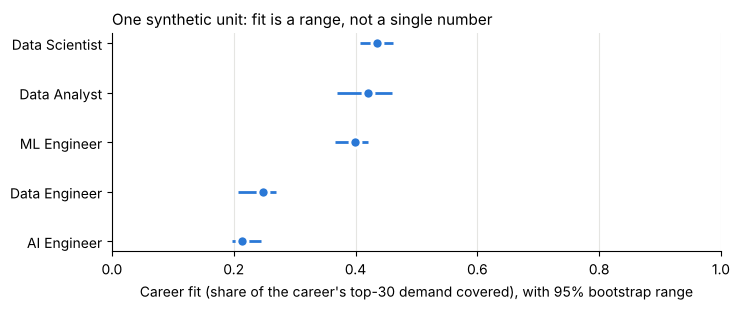

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
f = fit_strength.sort_values("fit")
y = np.arange(len(f))
ax.hlines(y, f.ci_low, f.ci_high, color="#2a78d6", lw=2)
ax.plot(f.fit, y, "o", color="#2a78d6", ms=8, mec="white", mew=2)
ax.set_yticks(y); ax.set_yticklabels(f.career); ax.set_xlim(0, 1)
ax.set_xlabel("Career fit (share of the career's top-30 demand covered), with 95% bootstrap range")
ax.set_title("One synthetic unit: fit is a range, not a single number", loc="left", fontsize=11)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e5e5e2", lw=.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Reading it.** Dots are the point estimate. Lines are the 95% bootstrap range from resampling the ads of each career. Careers with fewer ads (Data Analyst has 27) get visibly wider ranges, which is the honest answer to "how sure are we?". When two ranges overlap strongly, the ranking between those careers should not be over-interpreted.

## 3. A whole curriculum (synthetic demo units)

In [6]:
UNITS = {
 "Unit A: Data Wrangling": """Unit overview
This unit introduces data handling. Students may have seen Git before.
Learning outcomes
By the end of this unit students will be able to clean data with Python and pandas and query databases with SQL.
Weekly schedule
Week 1: Python and pandas basics. Week 2: SQL joins and aggregation. Week 3: Exploratory data analysis with matplotlib.
Assessment
Assignment 1 is a SQL project. Assignment 2 is a pandas data cleaning report.""",
 "Unit B: Machine Learning": """Unit overview
An applied unit on machine learning.
Learning outcomes
Students will be able to train and evaluate regression and classification models with scikit-learn.
Weekly schedule
Week 1: Regression. Week 2: Classification and model evaluation. Week 3: Neural networks in PyTorch. Week 4: Natural language processing and transformers.
Assessment
The final project is a machine learning model built with scikit-learn and presented to a client.""",
 "Unit C: Statistics": """Unit overview
Foundations of statistics for data science.
Weekly schedule
Week 1: Probability. Week 2: Hypothesis testing. Week 3: Regression and statistics in R. Week 4: A/B testing.
Assessment
The exam covers statistics and A/B testing.""",
 "Unit D: Data Visualisation": """Unit overview
Communicating data. Students are shown Docker and AWS only briefly in the last lecture.
Weekly schedule
Week 1: Tableau dashboards. Week 2: Storytelling with data. Week 3: Power BI.
Assessment
Assessment 1 is a Tableau dashboard."""}
profiles = {u: analyse_text(t) for u, t in UNITS.items()}
cur = curriculum_coverage(profiles)
print(len(cur), "skills covered across", len(UNITS), "units")
pd.DataFrame([{"skill": s, "best level": d["best_level"], "units": ", ".join(u.split(":")[0] for u in d["units"])} for s, d in cur.items()]).sort_values("best level").head(12)

26 skills covered across 4 units


,skill,best level,units
8,Machine Learning,assessed,Unit B
20,A/B Testing,assessed,Unit C
24,Dashboarding,assessed,Unit D
11,scikit-learn,assessed,Unit B
10,Classification,assessed,Unit B
9,Regression,assessed,"Unit B, Unit C"
7,Data Cleaning,assessed,Unit A
17,Statistics,assessed,Unit C
23,Tableau,assessed,Unit D
3,SQL,assessed,Unit A


In [7]:
curr_w = {s: d["weight"] for s, d in cur.items()}
fit_cur = M.fit(curr_w, n_boot=500)
fit_cur.round(3)

,career,n_ads,fit,ci_low,ci_high
0,Data Scientist,127,0.575,0.543,0.609
1,Data Analyst,27,0.475,0.415,0.530
2,ML Engineer,202,0.390,0.353,0.417
3,Data Engineer,57,0.231,0.184,0.257
4,AI Engineer,275,0.156,0.145,0.188


### The alignment map: demand by career, with curriculum coverage overlaid
Shade = how strongly the market demands the skill for that career (one hue, darker = more). The bracket after each skill name is its best coverage in the curriculum: **[A]** assessed, **[T]** taught, **[M]** mentioned, **[ ]** not covered. Dark rows with an empty bracket are the gaps that matter most. The generic term *Artificial Intelligence* is left out of the map and the gap list because it is too vague to act on.

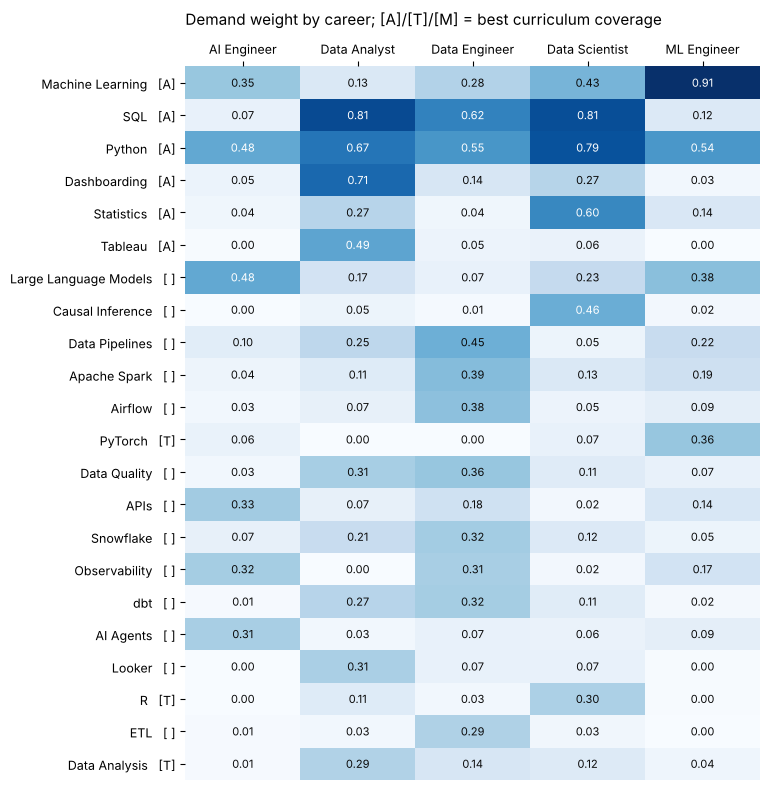

In [8]:
UMBRELLA = ["Artificial Intelligence"]          # too generic to act on, so left out of the map and the gap list
top = D.drop(columns=UMBRELLA).max(axis=0).sort_values(ascending=False).head(22).index
H = D[top].T[M.names]
fig, ax = plt.subplots(figsize=(7.8, 8))
im = ax.imshow(H.values, cmap="Blues", vmin=0, vmax=max(0.8, H.values.max()), aspect="auto")
ax.set_xticks(range(len(M.names))); ax.set_xticklabels(M.names, rotation=0, fontsize=9)
letter = {"assessed": "A", "taught": "T", "mentioned": "M"}
ax.set_yticks(range(len(H)))
ax.set_yticklabels([f"{s}   [{letter[cur[s]['best_level']]}]" if s in cur else f"{s}   [ ]" for s in H.index], fontsize=9)
ax.xaxis.tick_top()
for i, s in enumerate(H.index):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.45 else "#0b0b0b")
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Demand weight by career; [A]/[T]/[M] = best curriculum coverage", loc="left", fontsize=11, pad=30)
plt.tight_layout(); plt.show()

### Biggest gaps for the best-fitting career

In [9]:
best = fit_cur.career.iloc[0]
print("Best fit:", best, f"({fit_cur.fit.iloc[0]:.2f}, 95% range {fit_cur.ci_low.iloc[0]:.2f} to {fit_cur.ci_high.iloc[0]:.2f})")
M.gaps(curr_w, best, k=8, exclude=UMBRELLA)

Best fit: Data Scientist (0.57, 95% range 0.54 to 0.61)


,skill,demand,current_coverage,marginal_gain
0,Causal Inference,0.457,0.0,0.457
1,Large Language Models,0.230,0.0,0.230
2,Experiment Design,0.207,0.0,0.207
3,Forecasting,0.181,0.0,0.181
4,Apache Spark,0.128,0.0,0.128
5,Snowflake,0.124,0.0,0.124
6,Data Quality,0.108,0.0,0.108
7,dbt,0.106,0.0,0.106


## 4. Using real outlines
Replace the synthetic units with real PDFs:
```python
import glob, os
profiles = {os.path.basename(p): analyse_study_material(p) for p in glob.glob("unit_outlines/*.pdf")}
```
Put the PDFs in a `unit_outlines` folder next to this notebook, then re-run from section 3.

## 5. Limitations (state these in the report)
* **Demo units are synthetic**, so nothing here is a result about a real degree.
* Coverage level is a **heuristic from headings and cue words**; unusual outline layouts can be mis-tagged, so spot-check evidence sentences.
* The weights (assessed 1.0, taught 0.75, mentioned 0.5) are hyper-parameters, not measured quantities. Run a sensitivity check as in notebook 04.
* The bootstrap captures **sampling noise in the ads only**, not bias from where the ads came from (large tech companies, U.S. market).
* The coverage tagger keeps a section’s level until the next heading, so a stray sentence at the end of an assessment section can be tagged “assessed”. Spot-check the evidence.
* Fit measures overlap with market demand, not employability or mastery.